# Perceptrons

## Setup

In [1]:
## if using Colab, you need to run this every time you start a notebook
## on a local installation, you only need to run this once (or install the
## pyMLaux package outside of the notebook once and for all)
!pip install git+https://github.com/UBod/pyMLaux.git
!pip install tqdm ipywidgets

  Cloning https://github.com/UBod/pyMLaux.git to C:\Users\Elias\AppData\Local\Temp\pip-req-build-cj8sv9lf
  Resolved https://github.com/UBod/pyMLaux.git to commit bf7c7e39ae37cb55c6fd06dca3ae7d53f4a82086
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'


  Running command git clone --filter=blob:none --quiet https://github.com/UBod/pyMLaux.git 'C:\Users\Elias\AppData\Local\Temp\pip-req-build-cj8sv9lf'


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import random
from tqdm.notebook import tqdm

In [3]:
#Plotting for non binary predictions.
def predict_2d_for_plotting(x, y, func):
    X, Y = np.meshgrid(x, y)
    Xmat = np.column_stack([X.reshape(X.size), Y.reshape(Y.size)])
    Z = func(Xmat).reshape(x.size, y.size)
    return(X, Y, Z)

def plot_2d_prediction_heatmap(x, y, func, xval, yval, label=None, figsize=(8, 8), levels=np.linspace(0,1,20), alpha =0.2):
    X, Y, Z = predict_2d_for_plotting(xval, yval, func)

    fig, ax = plt.subplots(figsize=figsize)
    if label and len(label):
        fig.suptitle(label)
    ax.contourf(X, Y, Z, cmap='bwr', levels=levels, alpha= alpha)
    ax.scatter(np.array(x)[:, 0], np.array(x)[:, 1], c=y, cmap='bwr')
    plt.close(fig) 
    return fig

## The Logistic Regression Training Algorithm

In [4]:
def sigmoid(z): 
    return 1 / (1 + np.exp(-z))

In [5]:
def log_regr(x, w):
    #calculate activiation from inputs and weights.
    l = x.shape[0]
    ones = np.ones(shape=(l,1))

    xn = np.concatenate([x, ones], axis=1)
    net = xn @ w.T
    a = sigmoid(net)
    return(a)

In [13]:
def train_log_regr(X, y, w, eta=0.1, maxiter=1000):
    l, d = X.shape
    print(l, d, len(w))
    assert (d + 1) == len(w)
    iter = 0
    for iter in tqdm(range(maxiter)):
        iter = iter + 1
        print('Epoch ', iter, ' =============================================')
        r = list(range(X.shape[0]))
        random.shuffle(r)
        for i in r:
            #Weight update!
            a = log_regr(X[i,:].reshape(1,d), w)
            delta = a - y[i]
            w =- eta * delta * np.concatenate([X[i,:], [1]])
        print('Weight vector: ', w)
    return w

In [7]:
X = np.array([[0.1, 0.5], [0.2, 0.9], [0.4, 0.7], [0.5, 0.8],
              [0.4, 0.2], [0.6, 0.3], [0.7, 0.05], [0.8, 0.5]])
y = np.array([1, 1, 1, 1, 0, 0, 0, 0])

In [8]:
X = np.array([[0.3, 0.8], [0.6, 0.4]])
y = np.array([1, 0])

In [9]:
w = np.array([-1, 2, 2]) ## initial value of weight vector

In [10]:
fig = plot_2d_prediction_heatmap(X, y, lambda x: log_regr(x, w),
                           xval=np.linspace(-0.1, 1.1, 101),
                           yval=np.linspace(-0.1, 1.1, 101))

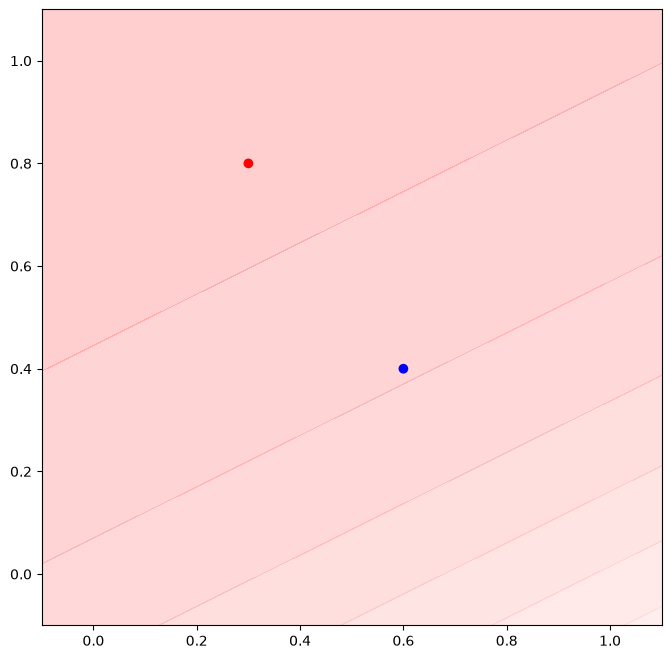

In [11]:
fig

In [12]:
w_final = train_log_regr(X, y, w, eta=0.1, maxiter=1000)

2 2 3


  0%|          | 0/1000 [00:00<?, ?it/s]

Epoch  1  =============================================


UFuncTypeError: Cannot cast ufunc 'subtract' output from dtype('float64') to dtype('int64') with casting rule 'same_kind'

In [17]:
w_final

array([-0.03107417, -0.02071611, -0.05179028])

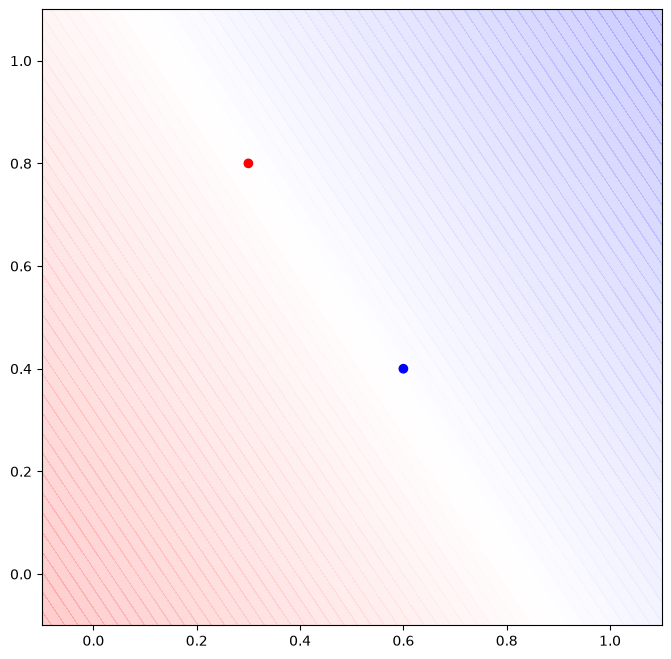

In [15]:
plot_2d_prediction_heatmap(X, y, lambda x: log_regr(x, w_final),
                   xval=np.linspace(-0.1, 1.1, 101), yval=np.linspace(-0.1, 1.1, 101),levels=100)

## Fit and predict on a dataset!

We will use the [Titanic Dataset](https://elearning.fh-ooe.at/mod/resource/view.php?id=640991) from elearning.

In [30]:
import pandas as pd
from sklearn.model_selection import train_test_split

In [16]:
df = pd.read_csv('../data/Titanic-Dataset.csv')

In [17]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [18]:
df.drop(columns=["PassengerId", "Name", "Sex", "Ticket", "Cabin", "Embarked"], inplace=True)

In [20]:
df.dropna(inplace=True)

In [24]:
data = df.to_numpy()
X = data[:,1:]
y = data[:,0]


In [29]:
w = np.random.standard_normal((X.shape[1]+1))

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [32]:
w_final = train_log_regr(X, y, w, eta=0.1, maxiter=1000)

714 5 6


  0%|          | 0/1000 [00:00<?, ?it/s]

Epoch  1  =============================================
Weight vector:  [-5.18505789e-10 -2.93819947e-09 -0.00000000e+00 -0.00000000e+00
 -2.49890408e-09 -1.72835263e-10]
Epoch  2  =============================================
Weight vector:  [0.1 4.  0.  0.  3.1 0.1]
Epoch  3  =============================================
Weight vector:  [-0.05 -1.45 -0.05 -0.   -3.33 -0.05]
Epoch  4  =============================================
Weight vector:  [0.2  5.   0.   0.   1.05 0.1 ]
Epoch  5  =============================================
Weight vector:  [-0.3  -0.1  -0.5  -0.2  -4.69 -0.1 ]
Epoch  6  =============================================
Weight vector:  [-0.3     -2.2     -0.      -0.      -0.72292 -0.1    ]
Epoch  7  =============================================
Weight vector:  [-0.15     -1.65     -0.       -0.       -0.433125 -0.05    ]
Epoch  8  =============================================
Weight vector:  [-0.15    -1.05    -0.      -0.      -0.38875 -0.05   ]
Epoch  9  =======

C:\Users\Elias\AppData\Local\Temp\ipykernel_21400\2945514861.py:2: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


Weight vector:  [-0.28435393 -1.80090823 -0.         -0.         -0.         -0.09478464]
Epoch  378  =============================================
Weight vector:  [-0. -0. -0. -0. -0. -0.]
Epoch  379  =============================================
Weight vector:  [0.2 2.5 0.1 0.1 3.  0.1]
Epoch  380  =============================================
Weight vector:  [-0.3     -6.1     -0.      -0.      -0.62375 -0.1    ]
Epoch  381  =============================================
Weight vector:  [-0.3    -0.3    -0.3    -0.1    -2.1075 -0.1   ]
Epoch  382  =============================================
Weight vector:  [ -0.1      -2.4      -0.       -0.1     -24.75208  -0.1    ]
Epoch  383  =============================================
Weight vector:  [ 0.1      5.8      0.       0.1     15.34625  0.1    ]
Epoch  384  =============================================
Weight vector:  [-2.35615053e-76 -4.29997471e-75 -0.00000000e+00 -2.35615053e-76
 -3.06299569e-75 -1.17807526e-76]
Epoch  385  =====